# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.fm Decision Tree - Predicting Time of Day and Next Track
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 9th November 2026*

---

## Research question

**Predict which artist comes next, using the artist that just played plus the hour and weekday**

 The previous artist is turned into one hot columns because it is not a number

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

plays = pd.read_csv('../datasets/scrobbles.csv')
print(plays.columns.tolist())

['artist', 'album', 'song', 'url', 'date', 'timestamp', 'date_only', 'hour', 'tod', 'month', 'is_loved']


Before training anything I need numbers to beat. 

The biggest class baseline is what you get by always guessing the most common artist, which is other. The repeat baseline is what you get by always guessing whatever artist just played. The repeat one is much higher and it is the real benchmark

In [23]:
TIME_COL = 'timestamp'  

plays[TIME_COL] = pd.to_datetime(plays[TIME_COL])  
plays = plays.sort_values(TIME_COL).reset_index(drop=True)

plays['hour'] = plays[TIME_COL].dt.hour
plays['weekday'] = plays[TIME_COL].dt.weekday

top = plays['artist'].value_counts().head(10).index
plays['artist_top'] = plays['artist'].where(plays['artist'].isin(top), 'other')
plays['prev_artist'] = plays['artist_top'].shift(1)
plays = plays.dropna(subset=['prev_artist']).reset_index(drop=True)

y, artist_names = pd.factorize(plays['artist_top'])
tod_names = pd.factorize(plays['tod'])
cut = int(len(plays) * 0.75)
print(len(plays), 'plays')
print(plays['artist_top'].value_counts())

17998 plays
artist_top
other                    6826
Arctic Monkeys           2230
Tame Impala              2041
Red Hot Chili Peppers    1559
Portishead               1199
Alice in Chains          1108
John Mayer                892
Ghost                     572
Morcheeba                 562
Pink Floyd                509
Massive Attack            500
Name: count, dtype: int64


In [24]:
X1 = plays[['hour', 'weekday']]
Xtrain, Xtest = X1.iloc[:cut], X1.iloc[cut:]
ytrain, ytest = y[:cut], y[cut:]

baseline = np.bincount(ytest).max() / len(ytest)
print('Baseline accuracy:', round(baseline, 3))

Baseline accuracy: 0.507


In [25]:
X2 = pd.concat([
    pd.get_dummies(plays['prev_artist'], prefix='prev', dtype=int),
    plays[['hour', 'weekday']]
], axis=1)

Xtrain2, Xtest2 = X2.iloc[:cut], X2.iloc[cut:]
ytrain2, ytest2 = y[:cut], y[cut:]

print('Feature matrix:', X2.shape)
print('Classes:', list(artist_names))
print('Train / test plays:', len(Xtrain2), '/', len(Xtest2))

Feature matrix: (17998, 13)
Classes: ['Tame Impala', 'Portishead', 'Red Hot Chili Peppers', 'Alice in Chains', 'other', 'Arctic Monkeys', 'Pink Floyd', 'John Mayer', 'Ghost', 'Massive Attack', 'Morcheeba']
Train / test plays: 13498 / 4500


In [26]:
majority = np.bincount(ytest2).max() / len(ytest2)
repeat = (plays['prev_artist'].iloc[cut:].values == plays['artist_top'].iloc[cut:].values).mean()
print('Baseline (biggest class):', round(majority, 3))
print('Baseline (repeat previous artist):', round(repeat, 3))

Baseline (biggest class): 0.507
Baseline (repeat previous artist): 0.898


A single tree at increasing depths. Training accuracy climbs to 1 but test accuracy stops improving around depth 12 and flatlines at 0.898. That 0.898 is exactly the repeat baseline, which is the first real result. The tree is just learning to say "whatever played last, play it again"

In [27]:
for depth in [2, 3, 5, 8, 12, None]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xtrain2, ytrain2)
    print('max_depth =', depth,
          ' train / test:', round(t.score(Xtrain2, ytrain2), 3),
          '/', round(t.score(Xtest2, ytest2), 3))

max_depth = 2  train / test: 0.519 / 0.596
max_depth = 3  train / test: 0.592 / 0.657
max_depth = 5  train / test: 0.694 / 0.729
max_depth = 8  train / test: 0.786 / 0.861
max_depth = 12  train / test: 0.833 / 0.898
max_depth = None  train / test: 0.833 / 0.898


Random forest on the same split. Accuracy is 0.898 which matches the repeat baseline exactly. The classification report shows high precision and recall across every artist but that is because most of the time the answer really is the same artist. The model is not doing anything clever, it is copying the previous artist

In [28]:
model2 = RandomForestClassifier(n_estimators=500, random_state=0)
model2.fit(Xtrain2, ytrain2)
ypred2 = model2.predict(Xtest2)

print('Forest train / test:',
      round(model2.score(Xtrain2, ytrain2), 3), '/',
      round(accuracy_score(ytest2, ypred2), 3))
print(classification_report(ytest2, ypred2,
                            target_names=list(artist_names),
                            zero_division=0))

Forest train / test: 0.833 / 0.898
                       precision    recall  f1-score   support

          Tame Impala       0.79      0.79      0.79       359
           Portishead       0.91      0.91      0.91       178
Red Hot Chili Peppers       0.91      0.91      0.91       311
      Alice in Chains       0.86      0.86      0.86       505
                other       0.93      0.93      0.93      2282
       Arctic Monkeys       0.86      0.86      0.86       303
           Pink Floyd       0.91      0.91      0.91        76
           John Mayer       0.90      0.91      0.91       184
                Ghost       0.82      0.82      0.82        82
       Massive Attack       0.84      0.84      0.84       118
            Morcheeba       0.91      0.91      0.91       102

             accuracy                           0.90      4500
            macro avg       0.88      0.88      0.88      4500
         weighted avg       0.90      0.90      0.90      4500



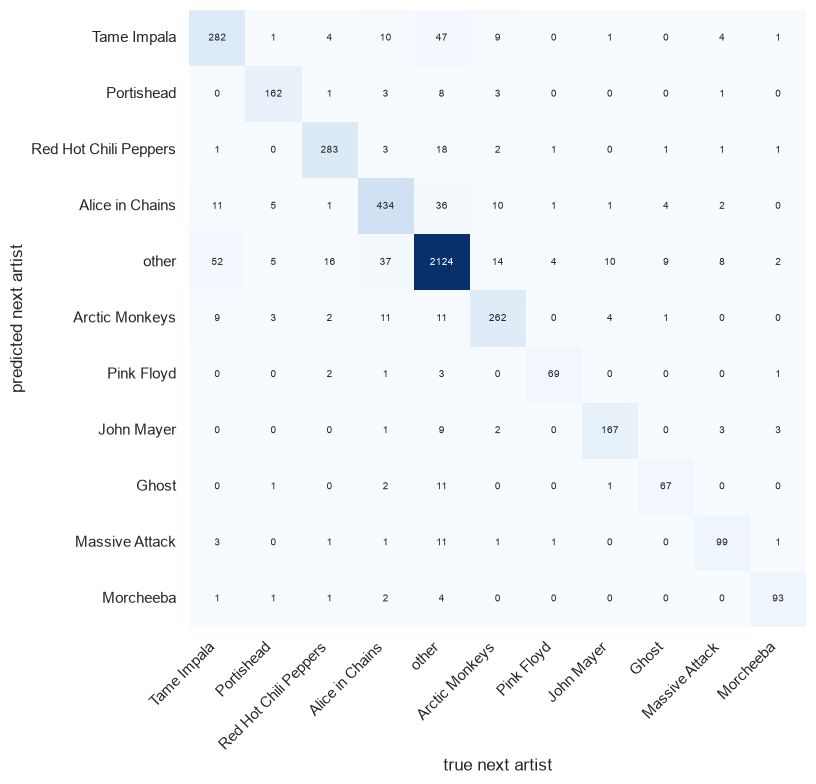

In [29]:
mat2 = confusion_matrix(ytest2, ypred2)

plt.figure(figsize=(9, 8))
sns.heatmap(mat2.T, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=artist_names, yticklabels=artist_names,
            annot_kws={'size': 7})
plt.xlabel('true next artist')
plt.ylabel('predicted next artist')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

scikit-learn documentation for plot_tree, the function used to draw the shallow tree\n",
"https://scikit-learn.org/1.5/modules/generated/sklearn.tree.plot_tree.html \n",
    "\n",

    
"scikit-learn example on feature importances with a forest of trees, the pattern I copied for the importance plot\n",
"https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html \n",